# **Pandas - Pay Equity Analysis Project**

### **Stage 0 - Importing and Loading dataset**

####**01 Importing dataset Excel file into pandas**





In [11]:
# Importing Python Libraries - Pandas, Numpy
import pandas as pd
import numpy as np

In [12]:
# Loading data from an excel file
raw = pd.read_excel("Excel_Pay_Equity_Analysis.xlsx", sheet_name = "RAW_DATA")
d = raw.copy() # creating copy for data manipulation
d = d.drop(columns = "Random_Sort") # removed unnesessary column

###**Stage 01 Audit - Observing dataset issues**

In [13]:
# Audit / observing the data to find the problems
print(f"Blank values / null values in each column: \n\n{d.isna().sum()}\n\n")
print(f"Unique values in each column : \n\n{d.nunique()}\n")

# LEG 2745 - need to check is it belongs to any dataset source?
print(d["employee_id"].str.contains("LEG").value_counts(),"\n\n")

# DUP 341 - need to check is it belongs to any dataset source?
print(d["employee_id"].str.contains("_DUP").value_counts(),"\n\n")

# Mixed datatype - string, integers and float (need to handle it carefully)
print(d["salary_raw"].map(type).value_counts(),"\n\n")

# Mixed formats like 22-09-2024, 22/9/2024 and datatypes - str, datetime
print(d["hire_date"].map(type).value_counts(),"\n\n")





Blank values / null values in each column: 

employee_id                    0
full_name                      0
source_dataset                 0
age                          553
gender                       539
ethnicity                   4524
education_level              866
years_experience             200
tenure_years                 182
department                     0
job_title                      0
country                        0
remote_status               2071
performance_rating           846
performance_review_score    2762
hire_date                      0
currency                       0
salary_raw                     0
pay_band                       0
dtype: int64


Unique values in each column : 

employee_id                 18000
full_name                   16136
source_dataset                  3
age                            49
gender                         15
ethnicity                       8
education_level                10
years_experience               41
tenure_y

#### **01 Key findings & Problems from the Data**



**Blanks:** There are blanks or null values present in few columns such as age(553), gender(539), ethnicity(4524), educ_level(866), years_exp(200), tenure_years(182), remote_status(2071),  perf_rating(846) and per_score(2762).

**Inconsistent Formatting:** There are inconsistent texts, dates, salary, symbols, trailing spaces or chars and whitespaces , especially in hire_date, salary, employee_id etc.

**incorrect Data types:** Incorrect data types and mixed data types, especially in salary_raw and hiredate

**Employee_id:** There are different employee ids, few are with LEG(2745) and few are with DUP(341). So we need to investigate if they are belong to the source datasets or is there any data quality issues.

**hire_date:** As the data is from the global company , so we need to formate the dates with their local time system.

 #### **02 Cross checking observation before proceeding to the data cleaning**

In [14]:
# cross check salary, hire date and other
d["salary_raw"].isna().sum() # 0 null values
d["hire_date"].isna().sum() #
d["tenure_years"].isna().sum() # 182 null values
print(d.info()) # All verified


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18000 entries, 0 to 17999
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   employee_id               18000 non-null  object 
 1   full_name                 18000 non-null  object 
 2   source_dataset            18000 non-null  object 
 3   age                       17447 non-null  float64
 4   gender                    17461 non-null  object 
 5   ethnicity                 13476 non-null  object 
 6   education_level           17134 non-null  object 
 7   years_experience          17800 non-null  float64
 8   tenure_years              17818 non-null  float64
 9   department                18000 non-null  object 
 10  job_title                 18000 non-null  object 
 11  country                   18000 non-null  object 
 12  remote_status             15929 non-null  object 
 13  performance_rating        17154 non-null  object 
 14  perfor

###**Stage 02 - Data Cleaning**

####**01 Removing Whitspaces or Trailing spaces**

In [15]:
# Data Cleaning

# 1: Removing whitespaces
text_cols = ['employee_id', 'full_name', 'gender', 'ethnicity', 'source_dataset',
             'job_title', 'department', 'education_level', 'remote_status',
             'performance_rating', 'currency', 'country', 'pay_band']

for col in text_cols:
  if col in d.columns:
    d[col] = d[col].str.strip()

####**02 Handling inconsistent string formating**

In [16]:
# 2: Standerizing text or formatting issues

# 1) Gender

d["gender"] = d["gender"].str.lower()

gender_mapping = {
    "male": "Male",
    "m": "Male",
    "man": "Male",
    "female": "Female",
    "f": "Female",
    "woman": "Female",
    "non-binary": "Non-binary",
    "nb": "Non-binary",
    "prefer not to say": "Prefer not to say",
    "other":"Other"
}

d["gender"] = d["gender"].map(gender_mapping)

# Check point
print(d["gender"].unique())
print(d["gender"].value_counts())

['Male' nan 'Female' 'Non-binary' 'Prefer not to say' 'Other']
gender
Male                 9140
Female               7646
Non-binary            403
Prefer not to say     136
Other                 136
Name: count, dtype: int64


In [17]:
# 2)Education_level

d["education_level"] = d["education_level"].str.lower()

education_mapping = {
    "phd.":"PhD",
    "phd":"PhD",
    "bsc":"Bachelors",
    "bachelor's degree":"Bachelors",
    "bachelors":"Bachelors",
    "bachelor's":"Bachelors",
    "master's":"Masters",
    "msc":"Masters",
    "high school":"High School",
    "associate degree":"Associate Degree" }

d["education_level"] = d["education_level"].map(education_mapping)


# Checkpoint
d["education_level"].unique()

array(['PhD', 'Bachelors', 'Masters', 'Associate Degree', nan,
       'High School'], dtype=object)

In [18]:
# 3) Performance Rating

d["performance_rating"] = d["performance_rating"].str.lower()

rating_mapping = {
    "meets":"Meets Expectations",
    "meets expectations":"Meets Expectations",
    "exceeds":"Exceeds Expectations",
    "exceeds expectations":"Exceeds Expectations",
    "below expectations":"Below Expectations" }

d["performance_rating"] = d["performance_rating"].map(rating_mapping)

# Checkpoint
print(d['performance_rating'].unique())
d['performance_rating'].value_counts()

['Meets Expectations' 'Exceeds Expectations' 'Below Expectations' nan]


,count
performance_rating,
Meets Expectations,9783
Exceeds Expectations,5877
Below Expectations,1494


In [19]:
# 4) Remote Status

d["remote_status"]= d["remote_status"].str.lower()

remote_status_mapping = {
    "on site":"On-site",
    "hybrid":"Hybrid",
    "remote":"Remote",
    "on-site":"On-site",
    "onsite":"On-site" }

d["remote_status"] = d["remote_status"].map(remote_status_mapping)

# Checkpoint
print(d["remote_status"].unique())

['On-site' 'Hybrid' nan 'Remote']


In [20]:
# 5) Country

country_mapping = {
    "India":"India",
    "Australia":"Australia",
    "Germany":"Germany",
    "France":"France",
    "Nigeria":"Nigeria",
    "Netherlands":"Netherlands",
    "South Africa":"South Africa",
    "Kenya":"Kenya",
    "Brazil":"Brazil",
    "Philippines":"Philippines",
    "Canada":"Canada",
    "Singapore":"Singapore",
    "UK":"United Kingdom",
    "United Kingdom":"United Kingdom",
    "US":"United States",
    "USA":"United States",
    "United States":"United States" }

d["country"] = d["country"].map(country_mapping)

# Checkpoint
print(d["country"].unique())

['United Kingdom' 'India' 'Australia' 'United States' 'Germany' 'France'
 'Nigeria' 'Netherlands' 'South Africa' 'Kenya' 'Brazil' 'Philippines'
 'Canada' 'Singapore']


In [21]:
# 6) Department

d["department"] = d["department"].str.lower()

department_mapping = {
    "legal":"Legal",
    "finance":"Finance",
    "engineering":"Engineering",
    "sales":"Sales",
    "product":"Product",
    "data science":"Data Science",
    "hr":"HR",
    "marketing":"Marketing",
    "operations":"Operations",
    "customer support":"Customer Support",
    "it":"IT",
    "design":"Design" }

d["department"] = d["department"].map(department_mapping)

# Checkpoint
print(d["department"].unique())

['Legal' 'Finance' 'Engineering' 'Sales' 'Product' 'Data Science' 'HR'
 'Marketing' 'Operations' 'Customer Support' 'IT' 'Design']


In [22]:
# Standerizing the job title

# 1. Lowercase and strip the column first
d['job_title'] = d['job_title'].str.lower().str.strip()

# 2. Complete mapping dictionary for all variants
job_title_mapping = {
    # Accounting & Finance roles
    'accountant': 'Accountant',
    'financial analyst': 'Financial Analyst',
    'finance manager': 'Finance Manager',
    'controller': 'Controller',
    'cfo': 'CFO',

    # Sales & Account Management roles
    'account executive': 'Account Executive',
    'sales rep': 'Sales Representative',
    'sales representative': 'Sales Representative',
    'sales manager': 'Sales Manager',
    'sales development rep': 'Sales Development Representative',
    'vp sales': 'VP of Sales',
    'vp of sales': 'VP of Sales',

    # Legal roles
    'paralegal': 'Paralegal',
    'legal counsel': 'Legal Counsel',
    'general counsel': 'General Counsel',

    # Engineering & IT roles
    'software engineer i': 'Software Engineer I',
    'software engineer ii': 'Software Engineer II',
    'senior software engineer': 'Senior Software Engineer',
    'staff engineer': 'Staff Engineer',
    'engineering manager': 'Engineering Manager',
    'devops engineer': 'DevOps Engineer',
    'qa engineer': 'QA Engineer',
    'ml engineer': 'Machine Learning Engineer',
    'machine learning engineer': 'Machine Learning Engineer',
    'systems administrator': 'Systems Administrator',
    'it manager': 'IT Manager',
    'it support specialist': 'IT Support Specialist',

    # Product & Design roles
    'product manager': 'Product Manager',
    'senior product manager': 'Senior Product Manager',
    'vp product': 'VP of Product',
    'vp of product': 'VP of Product',
    'product analyst': 'Product Analyst',
    'ux designer': 'UX Designer',
    'product designer': 'Product Designer',
    'design lead': 'Design Lead',
    'vp design': 'VP of Design',
    'vp of design': 'VP of Design',

    # Data roles
    'data analyst': 'Data Analyst',
    'data scientist': 'Data Scientist',
    'senior data scientist': 'Senior Data Scientist',
    'head of data': 'Head of Data',

    # HR & People roles
    'hr manager': 'HR Manager',
    'hr coordinator': 'HR Coordinator',
    'hr business partner': 'HR Business Partner',
    'recruiter': 'Recruiter',
    'vp people': 'VP of People',
    'vp of people': 'VP of People',

    # Executive roles
    'coo': 'COO',
    'cmo': 'CMO',

    # Marketing & Operations roles
    'marketing manager': 'Marketing Manager',
    'marketing coordinator': 'Marketing Coordinator',
    'content strategist': 'Content Strategist',
    'seo specialist': 'SEO Specialist',
    'operations manager': 'Operations Manager',
    'operations analyst': 'Operations Analyst',
    'logistics coordinator': 'Logistics Coordinator',

    # Customer Support roles
    'customer success manager': 'Customer Success Manager',
    'support agent': 'Support Agent',
    'support team lead': 'Support Team Lead'
}

# 3. Use .map() and fill any unmapped values back with the original column text
d['job_title'] = d['job_title'].map(job_title_mapping).fillna(d['job_title'])

# 4. Checkpoint to confirm you have 53 unique values
print("Unique job titles:", d['job_title'].nunique())


Unique job titles: 53


In [23]:
# Cross checking column count for cleaned department :
print(d["gender"].value_counts(),"\n")
print(d["ethnicity"].value_counts(),"\n")
print(d["performance_rating"].value_counts(),"\n")
print(d["remote_status"].value_counts(),"\n")
print(d["country"].value_counts(),"\n")
print(d["department"].value_counts(),"\n")

# Checkpoint Done
print(d[["gender", "ethnicity", "performance_rating", "remote_status", "country", "department"]].head(40))
print(d.isna().sum())
print(d.info())

gender
Male                 9140
Female               7646
Non-binary            403
Prefer not to say     136
Other                 136
Name: count, dtype: int64 

ethnicity
White                        6042
Asian                        2044
Hispanic or Latino           1734
Black or African American    1721
Two or More Races             813
Native American               427
Prefer not to say             423
Pacific Islander              272
Name: count, dtype: int64 

performance_rating
Meets Expectations      9783
Exceeds Expectations    5877
Below Expectations      1494
Name: count, dtype: int64 

remote_status
Remote     5971
On-site    5958
Hybrid     4000
Name: count, dtype: int64 

country
United States     3230
United Kingdom    2080
Philippines       1096
Germany           1095
Kenya             1076
South Africa      1076
Singapore         1072
India             1071
Netherlands       1067
Australia         1062
Brazil            1059
Canada            1012
France           

### **Stage 03 - Data Cleaning II - Handling Salary and Date**

#### **01 Cleaning date columns**

In [24]:
# Fixing unnessary data, symbols, formating

# 1) hire_date

# mixed datetime & str - formats - 2020/02/12,20202-03-14
d["hire_date"].map(type).value_counts()


# Converting data type into datetime only - ensuring day appears first
d["hire_date"] = pd.to_datetime(d["hire_date"], dayfirst = True, errors = "coerce")

# Final Checkpoint

# null count is 0 (correct)
print(f"Null value count: {d["hire_date"].isna().sum()}")

# Accurate - 18000 rows present
print(f"Non null count: {d['hire_date'].notna().sum()}")

# Upcoming futute date - December 2026 - valid
print(f"Latest Date: {d["hire_date"].max()}")

# Oldest date - July 2010 - again valid
print(f"Oldest Date: {d["hire_date"].min()}")

# Correct data type - datetime (valid)
print(f"Data Type: {d["hire_date"].dtype}")


Null value count: 0
Non null count: 18000
Latest Date: 2026-12-06 00:00:00
Oldest Date: 2010-07-15 00:00:00
Data Type: datetime64[ns]


####**02 Cleaning Salary column**

In [25]:
# 2) Salary

# 1. Clean salary column safely

# Inspecting salary_raw column - Before cleaning
print(f"Audit salary column - before cleaning:\n{d["salary_raw"].head(10)}\n\n")

# Cleaning unnecessary chars, spaces, comas, currency, symbols etc
d["salary_clean"] = (
    d["salary_raw"]
    .astype(str)
    .str.replace(r"[^0-9.]", "", regex=True)
    .str.replace(r"[iIlL]", "", regex=True)
)
# After cleaning - stored in salary_clean
print(f"After cleanin onto salary_clean :\n{d["salary_clean"].head(10)}\n\n")

# Converting blanks/null values into standard np.nan
d["salary_clean"] = d["salary_clean"].replace("", np.nan)

# Converting data type (str, int, float) into numeric (float) data type
d["salary_clean"] = pd.to_numeric(d["salary_clean"], errors="coerce")


# 2. Conversion of salaries into a common USD currency dollers

# Checking  currency column
print(f"Null count: {d['currency'].isna().sum()}") # 0 - valid
print(f"Non null count: {d['currency'].notna().sum()}") # 18000 - valid
print(f"Unique currency values:\n{d['currency'].unique()}") # 12 unique currencies - valid

# Converting all salaries into USD currency dollers

# Created a dictionary for mapping latest currency rates
rates = {
    "USD": 1.0000,
    "EUR": 1.1600,
    "GBP": 1.3527,
    "INR": 0.01046,
    "SGD": 0.7890,
    "NGN": 0.000754,
    "ZAR": 0.06196,
    "AUD": 0.7173,
    "BRL": 0.19521,
    "CAD": 0.7209,
    "KES": 0.00773,
    "PHP": 0.01596 }

# Calculating new salaries with the latest currency rates
d['salary_usd'] = d['salary_clean'] * d['currency'].map(rates)

# Rounding the decimal places
d["salary_usd"] = d["salary_usd"].round(2)


# Checkpoint

# Null values count - 0 (valid)
print(f"Null values : {d['salary_usd'].isna().sum()}")

# Non null count - 18000 (valid)
print(f"Non null values : {d['salary_usd'].notna().sum()}")

# Minimum value should be 245 (valid)
print(f"Lowest value: {d['salary_usd'].min()}")

# Minimum value should be 9909426 (valid)
print(f"Lowest value: {d['salary_usd'].max()}")



Audit salary column - before cleaning:
0         Â£50,117
1    3,520,010 INR
2            57008
3            78668
4         41666.97
5         56005.73
6      70015256.97
7            55251
8         Â£24,677
9         34398.23
Name: salary_raw, dtype: object


After cleanin onto salary_clean :
0          50117
1        3520010
2          57008
3          78668
4       41666.97
5       56005.73
6    70015256.97
7          55251
8          24677
9       34398.23
Name: salary_clean, dtype: object


Null count: 0
Non null count: 18000
Unique currency values:
['GBP' 'INR' 'AUD' 'USD' 'EUR' 'NGN' 'ZAR' 'KES' 'BRL' 'PHP' 'CAD' 'SGD']
Null values : 0
Non null values : 18000
Lowest value: 245.32
Lowest value: 9909426.69


### **Stage 04 - Handling Duplicates and blanks**

#### **01 Handling duplicates**

In [26]:
# Fixing and checking for duplicates in employee_id

# Inspecting employee id column

# 0 nulls
print(f"Null values : {d["employee_id"].isna().sum()}")

# unique values - 18000
print(f"Unique values : {d["employee_id"].notna().sum()}\n")

# Need to check - 2745 LEG (may be it relates/belongs to legacy data source)
print(f"employee_id count with LEG  : {d["employee_id"].str.contains("LEG").sum()}\n")

# Grouped employees by source dataset -
# confirmed the above 2745 rows belongs to the 'Acquired_company_legacy' Dataset - valid
print(f"Employee count by source dataset:\n{d.groupby("source_dataset")["employee_id"].count()}\n")

# Need to check - 341 DUP rows (where it comes?)
print(f"employee_id count with DUP count: {d["employee_id"].str.contains("_DUP").sum()}\n")

# BOOLEAN value for checking DUP
ids_with_DUP = d["employee_id"].str.contains("DUP")

# Extracting the employee_ids without DUP (exclude DUP ids)
base_ids = d["employee_id"].str.replace("_DUP", "")

# Checking for duplicates - base_ids with existig ids
twin_exist = base_ids.isin(d["employee_id"]) # duplicate exists

# Extracting duplicate employee_ids
drop_rows = ids_with_DUP & base_ids.isin(d["employee_id"])

# Safe check - 73 duplicates found
drop_rows = ids_with_DUP & twin_exist
print(f"Duplicates found:\n{drop_rows.value_counts()}\n\n")

# Removed duplicates
d = d[~drop_rows]

# Checkpoint
print(d.info())
print(d.shape) # total rows 17927 after removed duplicates

Null values : 0
Unique values : 18000

employee_id count with LEG  : 2745

Employee count by source dataset:
source_dataset
acquired_company_legacy    2745
hris_export_2023           8993
survey_response_2024       6262
Name: employee_id, dtype: int64

employee_id count with DUP count: 341

Duplicates found:
employee_id
False    17927
True        73
Name: count, dtype: int64


<class 'pandas.core.frame.DataFrame'>
Index: 17927 entries, 0 to 17999
Data columns (total 21 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   employee_id               17927 non-null  object        
 1   full_name                 17927 non-null  object        
 2   source_dataset            17927 non-null  object        
 3   age                       17379 non-null  float64       
 4   gender                    17393 non-null  object        
 5   ethnicity                 13422 non-null  object        
 6   education_level

####**02 Handling blank/null values**

In [27]:

 # Handling blank values

# Filling age
# Checking mean & median
print("Before filling age values:")
print(f"Mean value: {d["age"].mean().round()}") # 36
print(f"Median value: {d["age"].median()}") # 36
print(f"Null values {d["age"].isna().sum()}\n\n") # 548

# Both mean & median are same(normal distribution, not affected by outliers)
# So filling age with mean
d["age"] = d["age"].fillna(d["age"].mean().round()) # filled with 36

# converting age into numeric integer
d["age"] = pd.to_numeric(d["age"])

# Check point
print("After filling age values:")
print(f"Data type: {d['age'].dtype}")
print(f"Null count: {d['age'].isna().sum()}")
print(f"Non null count: {d['age'].notna().sum()}")


Before filling age values:
Mean value: 36.0
Median value: 35.0
Null values 548


After filling age values:
Data type: float64
Null count: 0
Non null count: 17927


In [28]:
# Filling Years of experience with mean
print(f"Null count: {d["years_experience"].isna().sum()}") # 200 nulls
print(f"Mean value: {d["years_experience"].mean()}") # 14.6
print(f"Median value: {d['years_experience'].median()}") # 14

#calculate avg for each pay band
band_mean_exp = d.groupby("pay_band")["years_experience"].transform("mean").round()

# Filling value with an average years of experience of each pay band
d["years_experience"] = d["years_experience"].fillna(band_mean_exp)


Null count: 200
Mean value: 14.687143904778022
Median value: 14.0


In [29]:
# Filling gender column
print(d["gender"].isna().sum()) # 670 null values
print(f"Each category count:\n{d["gender"].value_counts()}") # males are more, but we can choose safe method
print(f"Most frequent value: {d['gender'].mode()}") # males

# Filling with "prefer not to say" category - safer option
d["gender"] = np.where(d["gender"].isna(), "Prefer not to say", d["gender"])

# Converting data type into string
d["gender"] = d["gender"].astype("string")


534
Each category count:
gender
Male                 9101
Female               7618
Non-binary            402
Prefer not to say     136
Other                 136
Name: count, dtype: int64
Most frequent value: 0    Male
Name: gender, dtype: object


In [30]:
# Filling ethnicity column
print(f"Null values: {d["ethnicity"].isna().sum()}") # 4505 null values
print(f"Category count:\n{d["ethnicity"].value_counts()}")
print(f"Most frequent value: {d["ethnicity"].mode()}") # white

# filling with safer option - 'Prefer not to say'
d["ethnicity"] = d["ethnicity"].fillna("Prefer not to say")

# After filled
print(f"Category count:\n{d["ethnicity"].value_counts()}")

Null values: 4505
Category count:
ethnicity
White                        6028
Asian                        2033
Hispanic or Latino           1725
Black or African American    1712
Two or More Races             810
Native American               426
Prefer not to say             418
Pacific Islander              270
Name: count, dtype: int64
Most frequent value: 0    White
Name: ethnicity, dtype: object
Category count:
ethnicity
White                        6028
Prefer not to say            4923
Asian                        2033
Hispanic or Latino           1725
Black or African American    1712
Two or More Races             810
Native American               426
Pacific Islander              270
Name: count, dtype: int64


In [31]:
# Filling education level
print(f"Null values: {d["education_level"].isna().sum()}") # 859
print(f"Most frequent: {d["education_level"].mode()}") # Bachelors - most repeated value
d["education_level"] = np.where(d["education_level"].isna(), d["education_level"].mode(),d["education_level"])
d["education_level"] = d["education_level"].astype("string") # converted into string
d["education_level"].dtype # string

Null values: 859
Most frequent: 0    Bachelors
Name: education_level, dtype: object


string[python]

In [32]:
# filling remote status
print(f"Null count:{d["remote_status"].isna().sum()}") # 2066

# Both are equaly occured - Remote (5947), On-site (5932) - very tiny difference 15
print(f"Category count:\n{d["remote_status"].value_counts()}")

# Filing with unknown - safer option
d['remote_status'] = d['remote_status'].fillna("unknown")

# Unknown instead of unknown
d["remote_status"] = np.where(d['remote_status'] == 'unknown', "Unknown", d['remote_status'])

# Converting data type int to string
d["remote_status"] = d["remote_status"].astype("string")


Null count:2066
Category count:
remote_status
Remote     5947
On-site    5932
Hybrid     3982
Name: count, dtype: int64


In [33]:
# Filling performance rating

print(f"Null count: {d["performance_rating"].isna().sum()}") # nulls - 843

# Mode = Meets Expectation - but its not a good practice to tag meets expectations to all emp
print(f"Most frequent value: {d["performance_rating"].mode()}")  # Meets expectations

# Filling with 'not rated' - safe option
d["performance_rating"] = d["performance_rating"].fillna("Not rated")

# Converted data type into string
d["performance_rating"] = d["performance_rating"].astype("string")


Null count: 843
Most frequent value: 0    Meets Expectations
Name: performance_rating, dtype: object


In [34]:
# Filling performance score

print(f"Null value: {d["performance_review_score"].isna().sum()}") # 2748 nulls

print(f"Mean value: {d["performance_review_score"].mean().round(2)}") # 3.4

print(f"Median value: {d["performance_review_score"].median()}") #3.4

# Filling with mean (avg) value (both mean & median are same)
d["performance_review_score"] = d["performance_review_score"].fillna(d["performance_review_score"].mean().round(1))

# Debug
print(d["performance_review_score"].dtype)
print(d["performance_review_score"].head(10))

Null value: 2748
Mean value: 3.39
Median value: 3.4
float64
0    3.4
1    3.4
2    2.4
3    2.7
4    3.8
5    5.0
6    5.0
7    4.3
8    4.5
9    3.8
Name: performance_review_score, dtype: float64


In [35]:
# Filling tenure years with calculated tenure

# Checking null values
print(f"Null values: {d['tenure_years'].isna().sum()}") # 181

# Storing current date
current_date = pd.to_datetime("today")

# Display current date
print(f"Current date: {current_date}") # current date

# Calculating tenure - diff between hire_date to current date
tenure_calc = (current_date - d["hire_date"]).dt.days/365.25 # multiplying days with 365 to get year value

# Validate negative years - to ensure fresher to be appeared (those who haven't joined yet)
d["tenure_years"] = np.where(tenure_calc <= 0, 0, tenure_calc)

d["tenure_years"] = d["tenure_years"].round(1)

Null values: 181
Current date: 2026-10-19 05:50:43.504142


#### **03 Cross Checking**

In [36]:
# Final Check Point

# Checking for null count
print(f"Checking null values in each column:\n{d.isna().sum()}\n\n")

# Checking for Unique values
print(f"Checking unique values in each column:\n{d.nunique()}\n\n")

# Checking data types and other information
print(d.info(),'\n\n')

# Checking statistical information
print(f"Checking statistical information of each column:\n{d.describe()}\n\n")



Checking null values in each column:
employee_id                 0
full_name                   0
source_dataset              0
age                         0
gender                      0
ethnicity                   0
education_level             0
years_experience            0
tenure_years                0
department                  0
job_title                   0
country                     0
remote_status               0
performance_rating          0
performance_review_score    0
hire_date                   0
currency                    0
salary_raw                  0
pay_band                    0
salary_clean                0
salary_usd                  0
dtype: int64


Checking unique values in each column:
employee_id                 17927
full_name                   16136
source_dataset                  3
age                            49
gender                          5
ethnicity                       8
education_level                 5
years_experience               41
tenure_

### **Stage 05 - Handling Outliers**

####**01 Detecting & managing outliers in salary_usd column**

In [37]:
# Detecting outliers in salary_usd column

# Audit salary_usd for statistical investigation
print("Statistical Summary: \n")
print(f"Mean value: {d["salary_usd"].mean().round(2)}")
print(f"Median value: {d["salary_usd"].median()}")
print(f"Minimum value: {d["salary_usd"].min()}")
print(f"Maximum value: {d["salary_usd"].max()}\n\n")

# Calculating quartile values
print("Calculating quartile values\n")

# It returns the salary of the employees , whose salary lies below 25% other salaries
Q1 = d['salary_usd'].quantile(0.25)
print(f"Quartile 01: {Q1.round(2)}")

# It returns the salary of the employees , whose salary lies below 50% of the other salaries
Q2 = d['salary_usd'].quantile(0.50)
print(f"Quartile 02 (Median): {Q2.round(2)}") # half of the salaries - median

# It returns the salary of the employees , whose salary lies below 75% of the other salaries
Q3 = d['salary_usd'].quantile(0.75)
print(f"Quartile 03: {Q3.round(2)}")

# IQR - Inter Quartile Range
IQR = Q3 - Q1
print(f"IQR(Inter Quartile Range): {IQR.round(2)}")

# Calculating the upper bond and lower bond values
UB = Q3+(1.5*IQR)

# If salary is below -2211 then it consider as unusual salary (but in real company the min salary should be 15000 or above)
print(f"Upper Bond: {UB.round(2)}")

# If salary is above 91742 then it consider as unusual salary (outliers)
LB = Q1-(1.5*IQR)
print(f"Lower Bond: {LB.round(2)}")

# Skeewness in salary_usd column
print(f"Skew: {d["salary_usd"].skew()}")

# Managing the outliers by flaging as no/yes
# Yes for outliers(unusual or extreme values)
# No for inliers(normal values)

d["salary_outlier_flag"] = np.where((d['salary_usd']<= 15000) | (d['salary_usd'] >= 91742.92),"Yes", "No",)

print(d["salary_outlier_flag"].value_counts()) # 463 outliers valid

Statistical Summary: 

Mean value: 52259.59
Median value: 43118.47
Minimum value: 245.32
Maximum value: 9909426.69


Calculating quartile values

Quartile 01: 33021.16
Quartile 02 (Median): 43118.47
Quartile 03: 56509.86
IQR(Inter Quartile Range): 23488.7
Upper Bond: 91742.92
Lower Bond: -2211.9
Skew: 39.034141234626986
salary_outlier_flag
No     17464
Yes      463
Name: count, dtype: int64


### **Stage 06 - Categories - Creating buckets/groups for analysis**

####**01 Creating buckets/categories for age, tenure, and year_exp**

In [38]:
# Creating bucket for age
print(f"Low Age: {d['age'].min()}") # 20
print(f"High Age: {d["age"].max()}") # 68

# It creates a boundries
age_bins = [18, 30, 45, 70]

# It assigns labels for that boundries
age_labels = ["Young Professional", "Mid-Career", "Senior"]

# pd.cut() takes lables & bins to create a new column
d["age_group"] = pd.cut(d['age'], bins = age_bins, labels = age_labels)

print(d['age_group'].head(10))

Low Age: 20.0
High Age: 68.0
0                Senior
1            Mid-Career
2            Mid-Career
3            Mid-Career
4            Mid-Career
5                Senior
6    Young Professional
7            Mid-Career
8            Mid-Career
9    Young Professional
Name: age_group, dtype: category
Categories (3, object): ['Young Professional' < 'Mid-Career' < 'Senior']


In [39]:
# Creating bucket for tenure_years

# Audit column
print(f"Min value: {d["tenure_years"].min()}") # 0
print(f"Max value: {d["tenure_years"].max()}") # 16.2

# Creating group
tenure_bins = [-1, 2, 5, 17]
tenure_labels = ["Fresher", "Established", "Tenured"]
d["tenure_group"] = pd.cut(d["tenure_years"], bins = tenure_bins, labels = tenure_labels)

print(d["tenure_group"].head(40))

Min value: 0.0
Max value: 16.3
0     Established
1         Fresher
2         Tenured
3         Fresher
4     Established
5     Established
6         Tenured
7         Fresher
8     Established
9         Tenured
10    Established
11        Tenured
12        Tenured
13        Tenured
14    Established
15    Established
16    Established
17        Fresher
18    Established
19        Fresher
20        Fresher
21    Established
22        Tenured
23        Fresher
24        Fresher
25    Established
26        Tenured
27        Tenured
28        Fresher
29        Fresher
30        Fresher
31    Established
32        Fresher
33        Tenured
34        Tenured
35    Established
36        Tenured
37        Tenured
38    Established
39        Tenured
Name: tenure_group, dtype: category
Categories (3, object): ['Fresher' < 'Established' < 'Tenured']


In [40]:
# Creating a bucket/group for years_experience

# Inspect column
print(f"Min value: {d['years_experience'].min()}") # 0
print(f"Max value: {d['years_experience'].max()}") # 40

# Creating an exp_group/bucket
exp_bins = [-1, 5, 15, 45]
exp_labels = ["Junior", "Mid-Level", "Senior"]
d["years_exp_group"] = pd.cut(d["years_experience"], bins = exp_bins, labels = exp_labels)
print(d["years_exp_group"].head(40))


Min value: 0.0
Max value: 40.0
0        Senior
1        Senior
2        Senior
3        Senior
4        Senior
5        Senior
6     Mid-Level
7     Mid-Level
8     Mid-Level
9        Junior
10       Junior
11    Mid-Level
12       Senior
13       Senior
14    Mid-Level
15    Mid-Level
16    Mid-Level
17       Junior
18    Mid-Level
19       Junior
20       Junior
21       Junior
22    Mid-Level
23       Senior
24       Junior
25       Senior
26       Senior
27       Senior
28    Mid-Level
29       Junior
30       Junior
31       Senior
32       Senior
33    Mid-Level
34       Senior
35    Mid-Level
36    Mid-Level
37       Senior
38       Senior
39    Mid-Level
Name: years_exp_group, dtype: category
Categories (3, object): ['Junior' < 'Mid-Level' < 'Senior']


###**Stage 07 - Analysis**

#### **01 Workforce Overview**

In [41]:
# creating a variable to exclude outliers (keeping inliers/normal) values
ok = d[d['salary_outlier_flag']=="No"]

In [42]:
# Department headcount
print(f"Total employes in each Department:\n{d["department"].value_counts()}\n\n")

# Gender headcount
print(f"Employee count by Gender:\n{d["gender"].value_counts()}")

# Education level headcount
print(f"Employee count by Education level:\n{d["education_level"].value_counts()}\n\n")

# Remote status headcount
print(f"Employee count by Education level:\n{d["remote_status"].value_counts()}\n\n")



Total employes in each Department:
department
Customer Support    1558
Operations          1544
IT                  1534
Finance             1532
HR                  1501
Sales               1499
Product             1489
Data Science        1488
Marketing           1464
Legal               1452
Engineering         1436
Design              1430
Name: count, dtype: int64


Employee count by Gender:
gender
Male                 9101
Female               7618
Prefer not to say     670
Non-binary            402
Other                 136
Name: count, dtype: Int64
Employee count by Education level:
education_level
Bachelors           7684
PhD                 3504
Masters             3417
High School         1665
Associate Degree    1657
Name: count, dtype: Int64


Employee count by Education level:
remote_status
Remote     5947
On-site    5932
Hybrid     3982
Unknown    2066
Name: count, dtype: Int64




####**02 Salary Overview**

In [43]:
# Salary overviw without outliers

print("Overall Salary Overview\n")
print(f"Overall Average salary: {ok["salary_usd"].mean().round(2)}\n")
print(f"Median salary: {ok['salary_usd'].median()}\n")
print(f"Highest salary: {ok['salary_usd'].max()}\n")
print(f"Lowest salary: {ok['salary_usd'].min()}\n")
print(f"Standard deviation salary: {ok['salary_usd'].std()}\n")




Overall Salary Overview

Overall Average salary: 45371.46

Median salary: 42606.775

Highest salary: 91729.93

Lowest salary: 15116.45

Standard deviation salary: 15828.384194325728



####**03 Overall Gender Pay Gap**

In [44]:
print("Average Salary by gender\n")

# Calculating mean salary by gender
print(f"{ok.groupby("gender")["salary_usd"].mean()}\n")

# Creating variable
gender_salaries = ok.groupby("gender")["salary_usd"].mean()

# Salary difference - Male vs Female Avg salary
pay_gap = ((gender_salaries['Male'] - gender_salaries['Female']) / gender_salaries['Female']) * 100

# 6.2% pay gap
print(pay_gap.round(1))


Average Salary by gender

gender
Female               43990.639292
Male                 46709.609781
Non-binary           43630.559467
Other                44972.284286
Prefer not to say    44183.006539
Name: salary_usd, dtype: float64

6.2


####**04 Gender pay gap by department**

In [45]:
# Summarizing data
# Average salary by department for each gender
dept_gender_gap = ok.pivot_table(
    index = "department",
    columns = "gender",
    values = "salary_usd",
    aggfunc="mean"
)

# Gender pay gap by department
dept_gender_gap["gap_pct"] = (
(
    (
  dept_gender_gap['Male'] - dept_gender_gap['Female']
    ) / dept_gender_gap['Female']) * 100).round(2)

# Sorting gap_pct to show highest pay gap department (Design, Data Science etc )
print(dept_gender_gap.sort_values(by="gap_pct", ascending=False))


gender                  Female          Male    Non-binary         Other  \
department                                                                 
Design            43276.197635  47039.450253  46633.448889  57262.017500   
Data Science      41738.608264  45367.760722  42743.136875  45588.354167   
Legal             36418.647345  39280.011114  36862.588857  33645.813846   
Product           51819.271239  55798.146968  46485.411429  65092.780000   
Marketing         44131.376667  47294.234601  41417.599655  45864.934000   
HR                43710.949050  46257.442656  40616.231053  43779.720000   
IT                43364.982387  45765.138318  47807.854444  46185.418462   
Engineering       42462.704201  44804.091632  38598.084167  48623.485455   
Sales             43947.845516  46237.312115  45314.872143  36766.173846   
Customer Support  46073.690510  48448.981615  43747.136053  41995.695455   
Operations        46062.205778  48412.259812  50118.112143  43485.020000   
Finance     

####**05 Deeper Analysis(deeper check)**

In [46]:
# Gender pay gap by job title, experience

# Create a temporary variable to keep only male and female gender
mf = ok[ok['gender'].isin(['Male', 'Female'])]
mf['gender'].value_counts()

deep = mf.groupby(['job_title', 'years_exp_group', 'gender'], observed=True)['salary_usd'].agg(['mean', 'count']).round()

print(deep.head(10),'\n')

# unstack - it takes male and female which are in same row and create columns for male, female
side = deep.unstack('gender')
print(side)

# Calculating pay gap
side['side_pay_gap'] = ((side[('mean','Male')] - side[('mean','Female')]) / side[('mean','Female')])*100

side['side_pay_gap'].notna().sum()

# Filter records
big = side[(side[('count', 'Male')] >= 15) & (side[('count', 'Female')] >= 15)]

# counting rows to conclude pay_gap
print(len(big))
print('Overall pay gap:',big['side_pay_gap'].median())
print('Postive records that showing pay gap within same job title, experience etc: \n', (big['side_pay_gap'] > 0).sum())

                                             mean  count
job_title         years_exp_group gender                
Account Executive Junior          Female  33103.0     23
                                  Male    31546.0     29
                  Mid-Level       Female  32674.0     41
                                  Male    34424.0     59
                  Senior          Female  40499.0     35
                                  Male    45804.0     80
Accountant        Junior          Female  31233.0     25
                                  Male    32271.0     23
                  Mid-Level       Female  32650.0     44
                                  Male    33063.0     54 

                                      mean           count     
gender                              Female     Male Female Male
job_title         years_exp_group                              
Account Executive Junior           33103.0  31546.0     23   29
                  Mid-Level        32674.0  34424.0     41

####**06 Ethnicity Pay Gap**

In [47]:
# Checking average salary by ethnicity
# It does not showing any meaningful pattern
# All salaries are around mean

ethnicity_means = ok.groupby('ethnicity')['salary_usd'].mean().fillna("Prefer not to say")
print(ethnicity_means)
print('\n')

# Highest & lowest mean salary within ethnicity
max_mean = ethnicity_means.max()
min_mean = ethnicity_means.min()
print(f"Highest mean: {max_mean}\nLowest mean: {min_mean}")

# Difference - gap average
diff_mean = ((max_mean - min_mean) / min_mean) *100
print(f"Gap mean: {diff_mean}")

# gender count in ethnicity
print(ok.groupby('ethnicity')['gender'].count())





ethnicity
Asian                        45212.477118
Black or African American    45143.901521
Hispanic or Latino           45265.911608
Native American              45304.576005
Pacific Islander             44098.516136
Prefer not to say            45704.071350
Two or More Races            44797.637697
White                        45386.063695
Name: salary_usd, dtype: float64


Highest mean: 45704.07135039534
Lowest mean: 44098.516136363636
Gap mean: 3.640837276852861
ethnicity
Asian                        1971
Black or African American    1663
Hispanic or Latino           1685
Native American               413
Pacific Islander              264
Prefer not to say            4806
Two or More Races             786
White                        5876
Name: gender, dtype: int64


####**07 Checking relation between experience vs salary**

In [48]:
# Checking correlation - is any employees paid more based on experience?
print(ok["years_experience"].corr(ok['salary_usd']).round(2))

# weak positive correlation - 0.39

0.39


####**08 Average salary by Education level**

In [49]:
# Checking mean salary withing each education_level

print(ok.groupby('education_level')['salary_usd'].mean())
# Normal distribution - all salaries are around the mean

education_level
Associate Degree    45531.402798
Bachelors           45289.075873
High School         45099.969102
Masters             45376.461604
PhD                 45600.590512
Name: salary_usd, dtype: float64



###**Stage 08 - Charts and Visualization**




####**01 Gender pay gap by department - Bar chart**

/tmp/ipykernel_2543/1761514952.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  bars = sns.barplot(


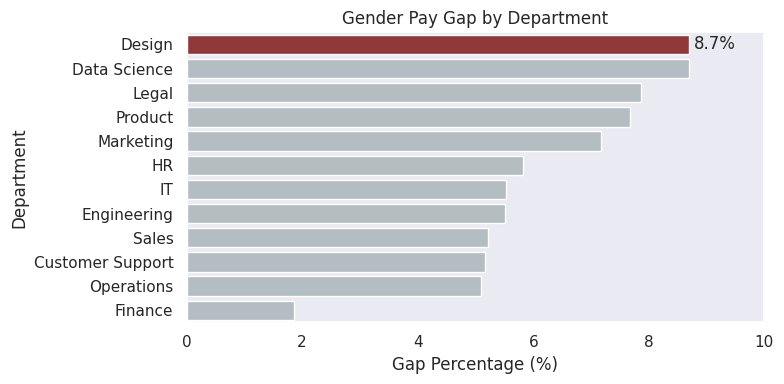

In [50]:
# Import libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Set global theme
sns.set_theme(style='dark')

# Create canvas / frame
fig, ax = plt.subplots(figsize=(8, 4))

# Sort values to ensure highest gap is processed correctly
sorted_depts = dept_gender_gap.sort_values(by='gap_pct', ascending=False)

# Calculate high_gap and define the palette BEFORE plotting
high_gap = sorted_depts['gap_pct'].max()
palette = ["#9e2a2b" if val == high_gap else '#b0bec5' for val in sorted_depts['gap_pct']]


# Create a horizontal bar chart and pass the custom palette in
bars = sns.barplot(
    data=sorted_depts,
    x='gap_pct',
    y='department',
    palette = palette,
    legend = False,
    errorbar=None,
    ax=ax
)

# Set limit to give room for labels
ax.set_xlim(0, 10)

# Add data labels directly without a loop
ax.bar_label(bars.containers[0], fmt='%.1f%%', padding=3)

# set title, labels, layout
plt.title("Gender Pay Gap by Department", color = '#2D3748')
plt.xlabel("Gap Percentage (%)", color = '#2D3748')
plt.ylabel('Department', color = '#2D3748')
fig.tight_layout()

# Save chart
fig.savefig('Gender_pay_gap.png', dpi = 150, bbox_inches = 'tight')

# Display chart
plt.show()

####**02 Salary distribution - Histogram**

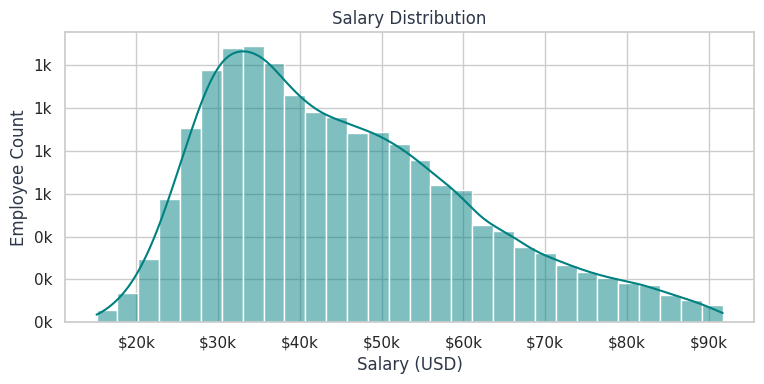

In [89]:
# Set global theme
sns.set_theme(style='whitegrid')

# Create canvas / frame
fig, ax = plt.subplots(figsize=(8, 4))

# create a histplot
sns.histplot(
    data = ok,
    x = 'salary_usd',
    bins = 30,
    kde = True,
    color = '#008080',
    ax = ax
)

# set a label
plt.title("Salary Distribution", color = '#2D3748')
plt.xlabel("Salary (USD)", color = '#2D3748')
plt.ylabel('Employee Count', color = '#2D3748')

# tight layout
fig.tight_layout()

# Formate numbers
from matplotlib.ticker import FuncFormatter

ax.xaxis.set_major_formatter(
        FuncFormatter (
        lambda x, pos: f"${x/1000:.0f}k"
    )
)
ax.yaxis.set_major_formatter(
    FuncFormatter (
        lambda x, pos: f"{x/1000:.0f}k"
    )
)

# Save image
fig.savefig('Salary_distribution_histogram.png', dpi = 150, bbox_inches = 'tight')

# Show the chart
plt.show()

####**03 Relationship between experience & salary - Scatterplot**

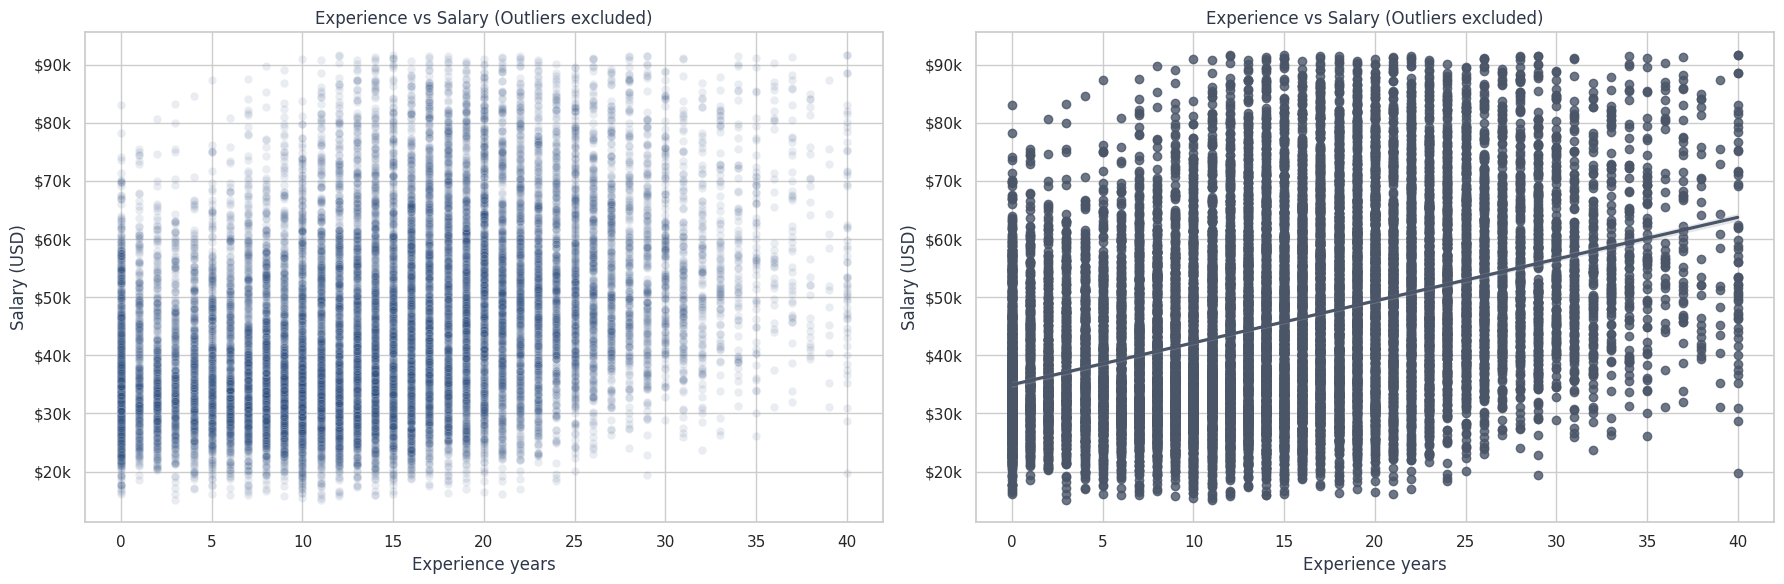

In [103]:
# Set a theme
sns.set_theme(style = 'whitegrid')

# Set a canva & frame
fig, axis = plt.subplots(1, 2,figsize = (18,6))

# create a scatter plot
sns.scatterplot (
    data = ok,
    x = 'years_experience',
    y = 'salary_usd',
    color = '#2B4C7E',
    alpha = 0.1,
    ax = axis[0]
)

# create a reg plot
sns.regplot (
    data = ok,
    x = 'years_experience',
    y = 'salary_usd',
    scatter = True,
    color = '#4A5568',
    ax = axis[1]
)

# Formate numbers
axis[0].yaxis.set_major_formatter(
    FuncFormatter (
        lambda x, pos: f"${x/1000:.0f}k"
    )
)

axis[1].yaxis.set_major_formatter(
    FuncFormatter (
        lambda x, pos: f"${x/1000:.0f}k"
    )
)

# set lables
axis[0].set_title('Experience vs Salary (Outliers excluded)', color = '#2D3748')
axis[0].set_xlabel('Experience years', color = '#2D3748')
axis[0].set_ylabel('Salary (USD)', color = '#2D3748')

axis[1].set_title('Experience vs Salary (Outliers excluded)', color = '#2D3748')
axis[1].set_xlabel('Experience years', color = '#2D3748')
axis[1].set_ylabel('Salary (USD)', color = '#2D3748')
fig.tight_layout()

# save image
fig.savefig('salary_vs_exp_relation.png', dpi = 150, bbox_inches = 'tight')

# show chart
plt.show()

####**04 Correlation Heatmap**

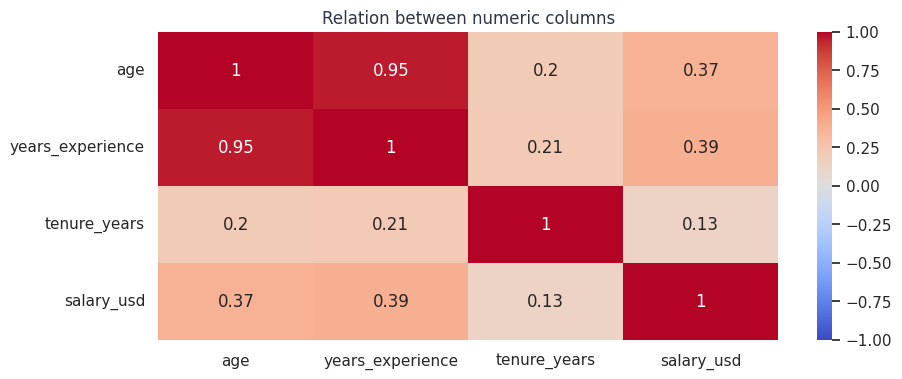

In [112]:
# Find correlation between age, exp, tenure years and salary
corr = ok[['age', 'years_experience', 'tenure_years', 'salary_usd']].corr()

# Set theme
sns.set_theme(style = 'whitegrid')

# Set a canva & Frame
fig, ax = plt.subplots(figsize = (10,4))

# Create a heatmap
sns.heatmap(
    data = corr,
    annot = True,
    vmin = -1,
    vmax = 1,
    cmap = 'coolwarm',
    color = '#2D3748',
    ax = ax
)

# Set a title
plt.title('Relation between numeric columns', color = '#2D3748')

# save image
fig.savefig('Correlatin_heatmap.png', dpi = 150, bbox_inches = 'tight')

# Display chart
plt.show()

####**05 Average vs median salary by department(side by side)**

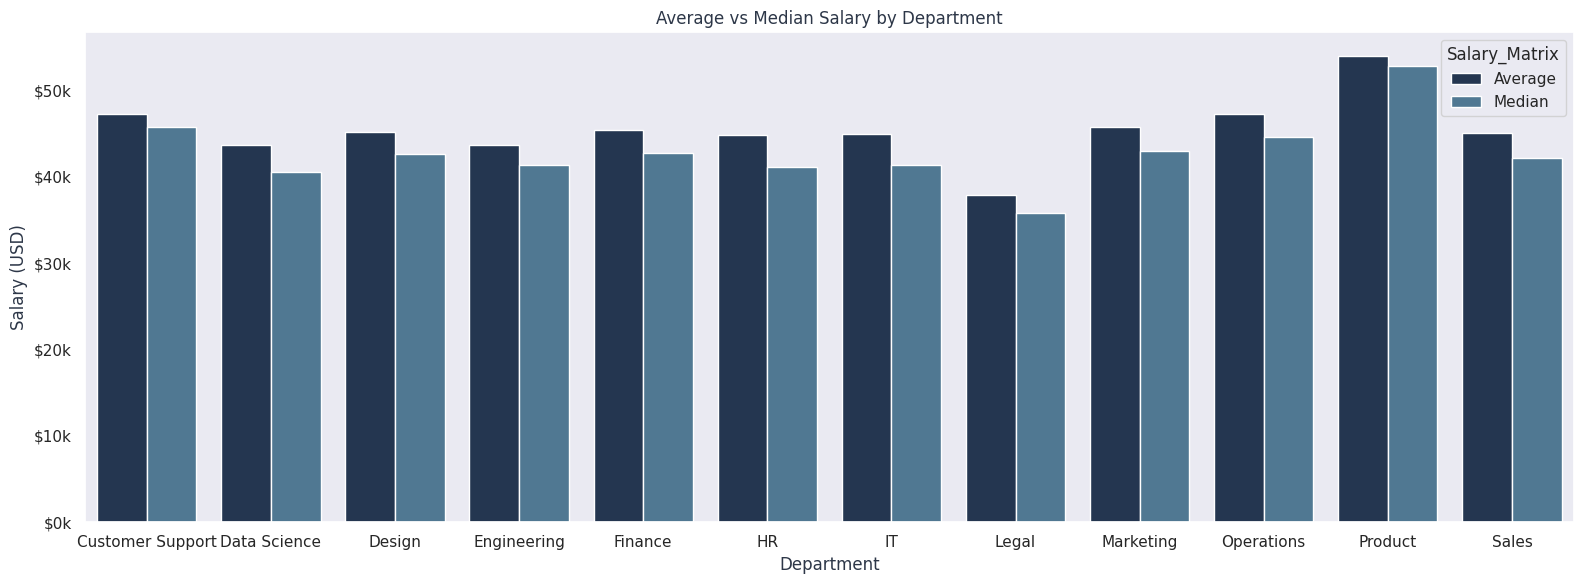

In [91]:
from matplotlib.ticker import FuncFormatter
# calculate department wise avg & median
dept_avg_summary = ok.groupby('department')['salary_usd'].agg(
    Average = 'mean',
    Median = 'median'
).reset_index()

# melt = It collaps data into a long formate in a single column , so seaborn can easily use it as hue
dept_melted = dept_avg_summary.melt(
    id_vars = 'department',
    value_vars = ['Average', 'Median'],
    var_name = 'Salary_Matrix',
    value_name = 'salary_usd',
)

dept_avg_summary = dept_avg_summary.sort_values(by='Average', ascending=False)
# Set global theme
sns.set_theme(style='dark')

# Set a color
custom_palette = {'Average': '#1D3557', 'Median': '#457B9D'}

# Create canvas / frame
fig, ax = plt.subplots(figsize=(16, 6))

# create a histplot
sns.barplot(
    data = dept_melted,
    x = 'department',
    y = 'salary_usd',
    palette = custom_palette,
    hue = 'Salary_Matrix',
    ax = ax
)

# set a label
plt.title("Average vs Median Salary by Department", color = '#2D3748')
plt.xlabel("Department", color = '#2D3748')
plt.ylabel('Salary (USD)', color = '#2D3748')

# Formate salary
ax.yaxis.set_major_formatter(
    FuncFormatter (
        lambda x, pos: f"${x/1000:.0f}k"
    )
)
# tight layout
fig.tight_layout()

# Save image
fig.savefig('Average_vs_median_salary.png', dpi = 150, bbox_inches = 'tight')

# Show the chart
plt.show()

###**Stage 09 - Project Summary & Workflow**




####**Title - Python Pay Equity Analysis**

####**01 Problem**

**What was the problem?**

- In multi-national companies having different employees from various countries, different ethnicity, & gender etc. In various coutries like UK, US and other, the companies need to provide a pay equality report to their Governments.

- They ensures all employees should get equal salaries, even if they are from different ethnicity, countries, genders and education level etc

#### **02 Business Questions**

01. is there employees getting equal salaries across all the departments?

02. Is there any pay gap between employees with different gender & ethnicity?

03. Is there employees paid based on factors like education level & experience?

04. is there employees getting salary in same currency (like USD) or not ?



####**03 Data Source**

* I used a real world messy raw dataset from Kaggle. which was about the employees pay equity data from a global company. It has employee details like names, emp_ids, ethnicity, gender, department, salary and other.

* It has contains 95K+ records , but I used only a random sample of 18k records.

* It was very messy , uncleaned dataset with mixed of date formates(hire_date), incorect data types, inconsistent formating, blanks/nulls, whites spaces , unnessary chars, symbls, currencies (salary_raw), different ids(employee_id) , trailing spaces and more.

* After cleaned the dataset and flagged outliers. The size reduced upto 17927 records (17464 without outliers).

#### **04 Data Cleaning Decisions**

**01 Cleaning the data**

- I applied statistical and Python Pandas built in methods or concepts for handling the data cleaning

- Removed whitespaces or hidden trailing spcaes.

- Standerized texts/strings and other to enusre consistent formatting across all the textual/categorical columns using Python map or other tools.

- Fixed incorrect data types to ensure smooth calculation on numerical/categorical data.

**salary column:**

- Fixed or removed the unnecessary symbols, spaces, chars or currencies from the salary_raw column and then
Stored it into the new salary_clean column.

- Then I converted the salary with latest currency rates to the usd dollers and stored it into the new salary_usd column.

**Employee Ids column:**

- I removed duplicates from the employee_id column. There was three types of formates - most of ids were similar, and some of them with LEG and DUP.

- I cross checked the LEG employee_ids with the legacy_acquired dataset source ids. 2745 records matched, which is valid

- I excluded the DUP ids and stored it as base ids. Then I matched it with an existing employee ids. I found 73 duplicates records. I removed all 73 entire records and kept valid DUP ids.

**Date column:**

- There was inconsistent data formates , some of were in dd-mm-yyyy formate, and some of like mm/dd/yyyy.

- So i converted all the date formates to the company's local date time formate, which is dd-mm-yyyy.

**02 Handling blanks / nulls**
I applied statistical methods and business scenarios to filling the blanks.

- I filled the ages with an average age (36), both mean and median were similar.

- I filled gender & ethnicity columns with 'Prefer not to say' to ensure safe filling and proper business use cases.

- I filled the tenure years by calculating the diifference between current date and hire date

- I used mean, median, mode , and business context or real world scenarious to fill the rest of the columns

**03 Handling Outliers**

- I filled the ages with an average age (36), both mean and median were similar. When I detected ouliers in age column, I found 68 as an outlier, but as real world scenario it was normal , so I kept it

- I detected 463 records as an outliers in a salary_usd column.
The highest salary was upto 9m while least salary is 245. So I kept salary from 15k to upto the Upper bond value based on real world scenario. Instead of removing outliers, I flagged them as salary_outlier_flag.

#### **05 Key Findings / Insights**

**01 Pay gap by gender**

There was an overall salary pay gap (upto 6.2%) between male and female across all the departments.

There was a high pay gap (upto 8.7%) found in the Design and Data Science departments while least in Finance.


**Pay gap by ethnicity**

There is no such a meaningful pattern found.



**Experience vs salary**

I obserevd there is a week positive correlation (upto 0.39). We can say that more experience employees get more salary. Salary does not relate with the experience.



**Education level vs salary**
Again there was no evidence found that showing high education employees get more salary



**Distibution of salary - mean vs median**
 The salary is slightly right skewed that pulling the average up. It means some senior employees, demanded skilled employees are getting slightly more salary (around 1k employees amoung all the employees)



 **Ultimate conclusion**
 There is a pay gap between gender amoung all the 12 departments and the salary is slightly right skewed and the other factors like education level, experience and other having no relation with the salary.

 Management should investigate salary pay in each departments.



####**05 Limitations**

01. Flagging the below 15k salaries based on real world scenario, but management should investigate why salaries are below 15k and it can be of frehser or trainee salaries also.

02. I kept pay band asetiz, beacuse it was not grouped properly. For example high earners were in the pay band 2, so management should go depper and set the proper salary range for each group.

03. I used my custom lables like prefer no to say, not rated, etc , but management should investigate is it because of data quality issue or something else.

04. I used the approximate currency exchange rates to convert all salary into a common usd dollers.

05. I used common local datetime formate (dd-mm-yyyy) for all the dates. Which was ambigious

In [ ]:
# Saving the cleaned data into Excel
d.to_excel('pandas_cleaned_pay_equity_data.xlsx', index=False)